# Signal propagation in the marmoset cortical network

**Author:** Xiaoge Bao  
**Affiliation:** Institut d’Investigacions Biomèdiques August Pi i Sunyer (IDIBAPS), Barcelona, Spain  
**Contact:** [XBAO@recerca.clinic.cat](mailto:XBAO@recerca.clinic.cat)  
**Date:** November 2026

This tutorial uses the **Marmoset Cortex Model** implementation and its 55-area cortical connectivity dataset, from this study: 

Li, G., Li, S., & Wang, X.-J. (2025). A hierarchy of time constants and reliable signal propagation in the marmoset cerebral cortex. *Nature Communications, 16*, 11640. [Article](https://doi.org/10.1038/s41467-025-66699-4)

**Original code and data:** [GitHub repository](https://github.com/GuanchunLi/Marmoset_Cortex_Model/)

In [1]:
from pathlib import Path
from contextlib import contextmanager, redirect_stdout
import base64, zlib, hashlib, importlib.util, io, os, copy, traceback
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

## 1 · Verified model files and initialization

In [2]:
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 13,
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Folder containing the three model files.
MODEL_DIR = (Path.cwd() / "model_data").resolve()

required_files = [
    "pre_functions_clean.py",
    "subgraph_data_marmoset.pkl",
    "hier_vals_fit.npy",
]

missing_files = [
    name for name in required_files
    if not (MODEL_DIR / name).is_file()
]
if missing_files:
    raise FileNotFoundError(
        f"Missing files in {MODEL_DIR}:\n"
        + "\n".join(missing_files)
        + "\nSet MODEL_DIR to the folder containing the extracted files."
    )

print("Model folder:", MODEL_DIR)

# Validate the numeric hierarchy array.
hierarchy = np.load(
    MODEL_DIR / "hier_vals_fit.npy",
    allow_pickle=False,
)
if hierarchy.shape != (55,) or not np.isfinite(hierarchy).all():
    raise ValueError("Expected a finite hierarchy array with shape (55,).")


@contextmanager
def model_directory():
    """Resolve relative data paths used by the original model."""
    previous = Path.cwd()
    try:
        os.chdir(MODEL_DIR)
        yield
    finally:
        os.chdir(previous)


# Load the original model functions.
spec = importlib.util.spec_from_file_location(
    "marmoset_original",
    MODEL_DIR / "pre_functions_clean.py",
)
pf = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pf)

# Load connectivity and initialize all model parameters.
with model_directory(), redirect_stdout(io.StringIO()):
    raw_parameters = pf.load_data("subgraph_data_marmoset.pkl")

    anatomical_fln = np.asarray(
        raw_parameters["fln_mat"], dtype=float
    ).copy()

    p, W = pf.genetate_net_connectivity(
        raw_parameters,
        LINEAR_HIER=0,
        IDENTICAL_HIER=0,
        FIT_HIER=1,
        LOCAL_IDENTICAL_HIERARCHY=0,
        ZERO_FLN=0,
        IDENTICAL_FLN=0,
        SHUFFLE_FLN=0,
        SHUFFLE_TYPE=0,
        STRONG_GBA=0,
        MACAQUE_CASE=0,
        GATING_PATHWAY=0,
        LONGRANGE_EI_ASYMMETRY=0,
        CONSENSUS_CASE=0,
        diverse_hi=41,
    )

required_parameters = [
    "beta_exc", "beta_inh",
    "tau_exc", "tau_inh",
    "wEE", "wEI", "wIE", "wII",
    "muEE", "muIE",
    "local_exc_scale", "local_inh_scale",
]
missing_parameters = [
    key for key in required_parameters if key not in p
]
if missing_parameters:
    raise RuntimeError(
        f"Incomplete initialization: {missing_parameters}"
    )

model_parameters = copy.deepcopy(p)
areas = list(p["areas"])

assert anatomical_fln.shape == (len(areas), len(areas))
assert np.isfinite(anatomical_fln).all()
assert np.all(anatomical_fln >= 0)

print(f"Ready: {len(areas)} areas; full model parameters initialized.")

Model folder: /home/xiaogebao/Tutorial_made/model_data
Ready: 55 areas; full model parameters initialized.


## 2 · Structural connectivity: FLN

Structural connectivity FLN $F_{ij}$ is the Fraction of Labeled Neurons associated with the projection from source $j$ to target $i$. It is a dimensionless anatomical connection weight, not an effective synaptic gain.

Rows are receiving areas; columns are sending areas. Colors use a logarithmic scale because nonzero strengths span several orders of magnitude. Gray cells denote zero entries in the supplied matrix, not proof that a biological projection is absent. Areas are ordered by the fitted hierarchy. Local E–I coupling is specified separately from this matrix.

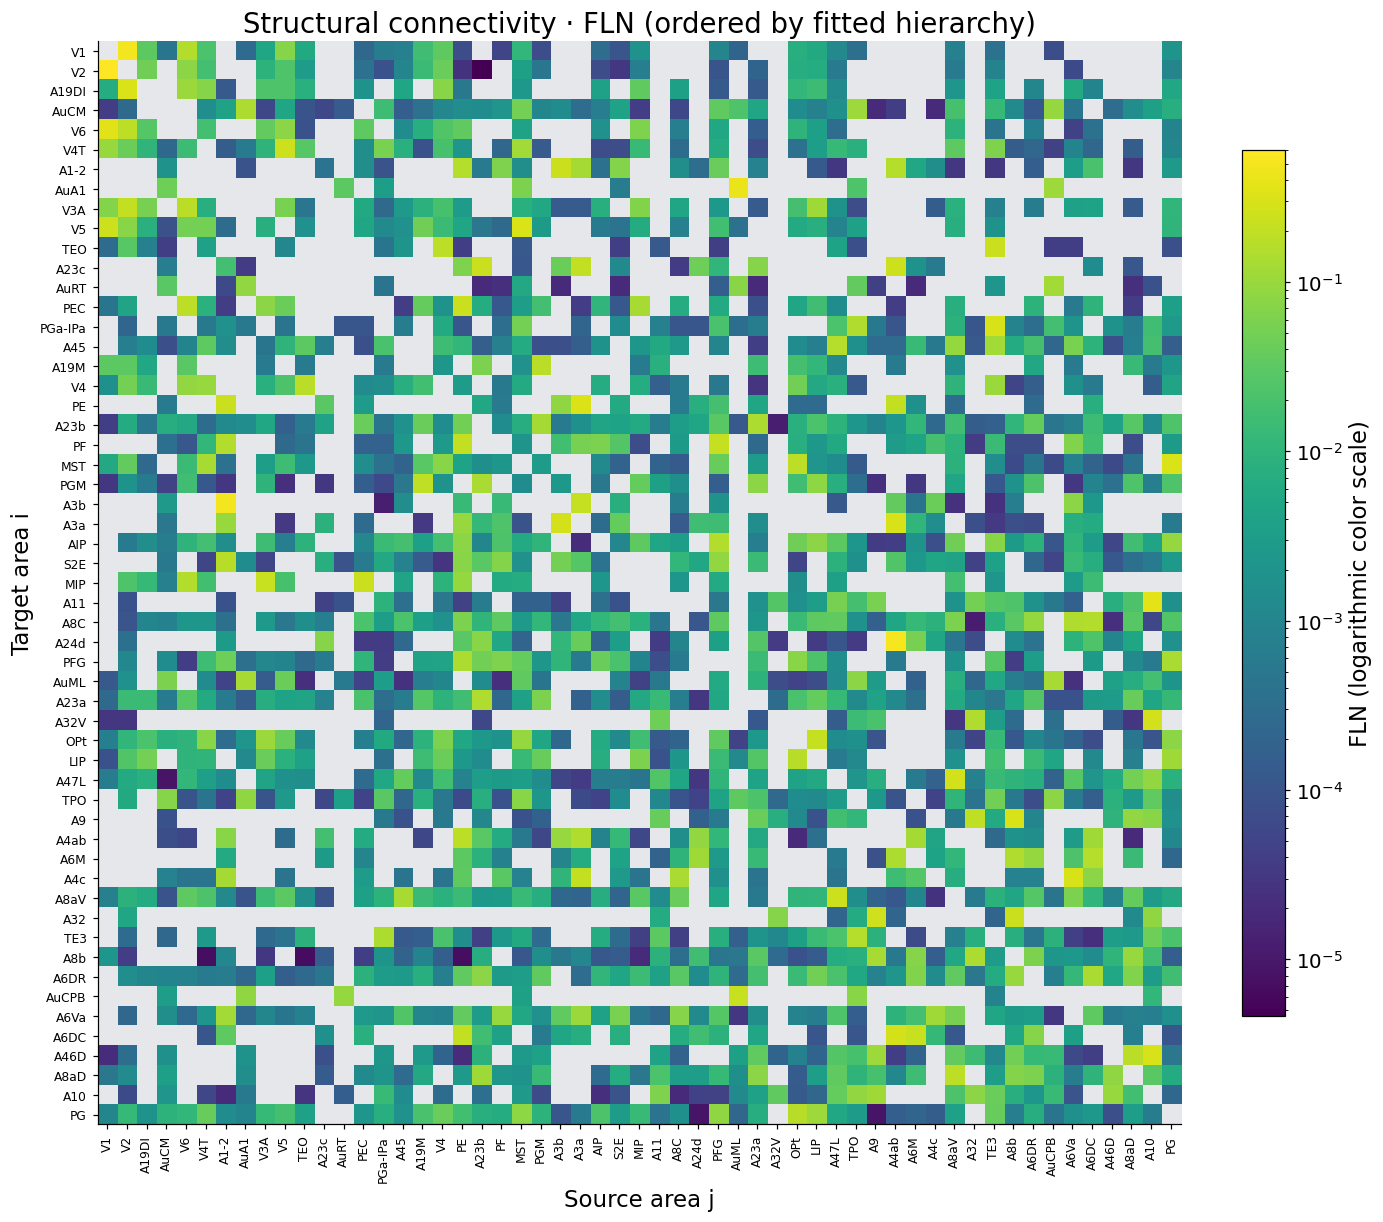

Nonzero off-diagonal entries: 1854 / 2970


In [3]:
order = np.argsort(np.asarray(p["hier_vals"]).reshape(-1), kind="stable")
F = anatomical_fln[np.ix_(order, order)]
positive = F[F > 0]
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("#e5e7eb")
fig, ax = plt.subplots(figsize=(13, 11), layout="constrained")
im = ax.imshow(np.ma.masked_less_equal(F, 0), origin="upper", cmap=cmap,
               norm=LogNorm(vmin=positive.min(), vmax=positive.max()))
labels = np.asarray(areas)[order]
ax.set_xticks(np.arange(len(areas)), labels, rotation=90, fontsize=8)
ax.set_yticks(np.arange(len(areas)), labels, fontsize=8)
ax.set(xlabel="Source area j", ylabel="Target area i",
       title="Structural connectivity · FLN (ordered by fitted hierarchy)")
fig.colorbar(im, ax=ax, shrink=0.8, label="FLN (logarithmic color scale)")
plt.show()
off_diagonal = ~np.eye(len(areas), dtype=bool)
print(f"Nonzero off-diagonal entries: {np.count_nonzero(anatomical_fln[off_diagonal])} / {off_diagonal.sum()}")

## 3 · Model equations and biophysical parameters

Each area $i$ contains an excitatory population $E$ and an inhibitory population $I$. The original simulation uses rectified population-rate dynamics, with $[z]_+=\max(z,0)$:

$$
\tau_E\frac{dr_E^i}{dt}=-r_E^i+\left[
\beta_E w_{EE}\ell_E^i r_E^i-\beta_E w_{EI}r_I^i
+\beta_E\mu_{EE}s_E^i\sum_j F_{ij}r_E^j+B_E^i+u_i(t)
\right]_+,
$$
$$
\tau_I\frac{dr_I^i}{dt}=-r_I^i+\left[
\beta_I w_{IE}\ell_I^i r_E^i-\beta_I w_{II}r_I^i
+\beta_I\mu_{IE}s_I^i\sum_j F_{ij}r_E^j+B_I^i
\right]_+.
$$

Hierarchy-dependent scaling is

$$
\ell_E^i=1+\eta_{E,\mathrm{local}}h_i,\quad
\ell_I^i=1+\eta_{I,\mathrm{local}}h_i,\quad
s_E^i=1+\eta_Eh_i,\quad s_I^i=1+\eta_Ih_i.
$$

In this configuration the E and I hierarchy profiles use the same fitted $h_i$. Long-range projections originate from E populations and drive both E and I populations in the receiving area.

| Symbol | Code parameter | Meaning | Units |
|---|---|---|---|
| $r_E^i,r_I^i$ | `r_exc`, `r_inh` | Population firing rates | Hz |
| $\tau_E,\tau_I$ | `tau_exc`, `tau_inh` | Local population relaxation times | ms |
| $\beta_E,\beta_I$ | `beta_exc`, `beta_inh` | Linear current-to-rate gains before rectification | Hz/pA |
| $w_{EE},w_{IE}$ | `wEE`, `wIE` | Local E→E and E→I coupling magnitudes | pA/Hz |
| $w_{EI},w_{II}$ | `wEI`, `wII` | Local I→E and I→I coupling magnitudes; minus signs are explicit | pA/Hz |
| $\mu_{EE},\mu_{IE}$ | `muEE`, `muIE` | Long-range E→E and E→I coupling scales | pA/Hz |
| $F_{ij}$ | `fln_mat[i,j]` | Anatomical projection from $j$ to $i$ | dimensionless |
| $h_i$ | `hier_vals[i]` | Fitted regional hierarchy score | dimensionless |
| $\eta_{E,\mathrm{local}},\eta_{I,\mathrm{local}}$ | `eta_local`, `eta_inh_local` | Local hierarchy modulation | dimensionless |
| $\eta_E,\eta_I$ | `eta`, `eta_inh` | Long-range hierarchy modulation at the receiving area | dimensionless |
| $B_E^i,B_I^i$ | `I_bkg_exc`, `I_bkg_inh` | Background drives chosen to maintain baseline firing | rate-equivalent Hz |
| $u_i(t)$ | `I_stim_exc[:,i]` | External drive added directly inside the E rate equation | rate-equivalent Hz |

**Baseline and input.** The simulation starts at $r_E^i=10$ Hz and $r_I^i=35$ Hz. For selected source $m$, we give the  square stimulus:

$$
u_i(t)=41.187\,\delta_{im}\,\mathbf{1}_{200<t\leq400\ \mathrm{ms}}.
$$

Here $\delta_{im}$ is the Kronecker delta.

In [4]:
parameter_labels = [
    ("tau_exc", "ms"), ("tau_inh", "ms"),
    ("beta_exc", "Hz/pA"), ("beta_inh", "Hz/pA"),
    ("wEE", "pA/Hz"), ("wEI", "pA/Hz"),
    ("wIE", "pA/Hz"), ("wII", "pA/Hz"),
    ("muEE", "pA/Hz"), ("muIE", "pA/Hz"),
    ("eta_local", "dimensionless"), ("eta_inh_local", "dimensionless"),
    ("eta", "dimensionless"), ("eta_inh", "dimensionless"),
]
rows = ["| Parameter | Value | Units |", "|---|---:|---|"]
rows += [f"| `{key}` | {p[key]:.8g} | {unit} |" for key, unit in parameter_labels]
display(Markdown("\n".join(rows)))

| Parameter | Value | Units |
|---|---:|---|
| `tau_exc` | 20 | ms |
| `tau_inh` | 10 | ms |
| `beta_exc` | 0.066 | Hz/pA |
| `beta_inh` | 0.351 | Hz/pA |
| `wEE` | 24.4 | pA/Hz |
| `wEI` | 19.7 | pA/Hz |
| `wIE` | 11.66038 | pA/Hz |
| `wII` | 12.5 | pA/Hz |
| `muEE` | 67.4 | pA/Hz |
| `muIE` | 49.810416 | pA/Hz |
| `eta_local` | 0.685 | dimensionless |
| `eta_inh_local` | 0.76 | dimensionless |
| `eta` | 0.685 | dimensionless |
| `eta_inh` | 0.76 | dimensionless |

## 4 · What the two response panels measure

**Maximal response:** the largest excitatory deviation above the 10 Hz baseline during the recorded interval,

$$P_i^{(m)}=\max_{0\leq t\leq T}\left(r_E^i(t)-10\right).$$

**Timescale:** the author's threshold-based duration, measured from stimulus offset $t_{\mathrm{off}}=400$ ms. To reproduce the original calculation, define

$$y_i(t)=r_E^i(t)-\min_{0\leq s\leq T}r_E^i(s),\qquad
P_{i,\mathrm{post}}=\max_{t\geq t_{\mathrm{off}}}y_i(t),$$
$$D_i^{(m)}=\max\{t-t_{\mathrm{off}}:t\geq t_{\mathrm{off}},\ y_i(t)>P_{i,\mathrm{post}}/e\}.$$

This duration includes any delayed post-offset rise. 

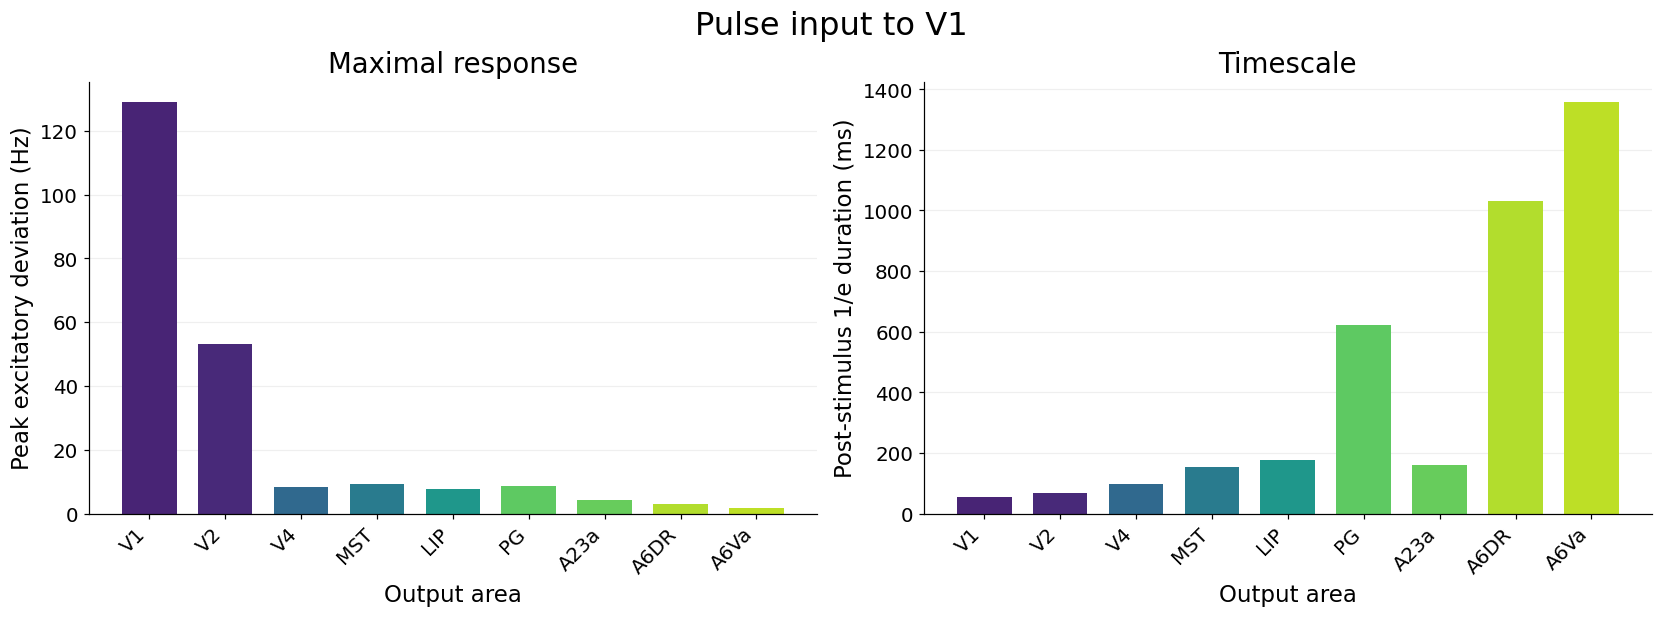

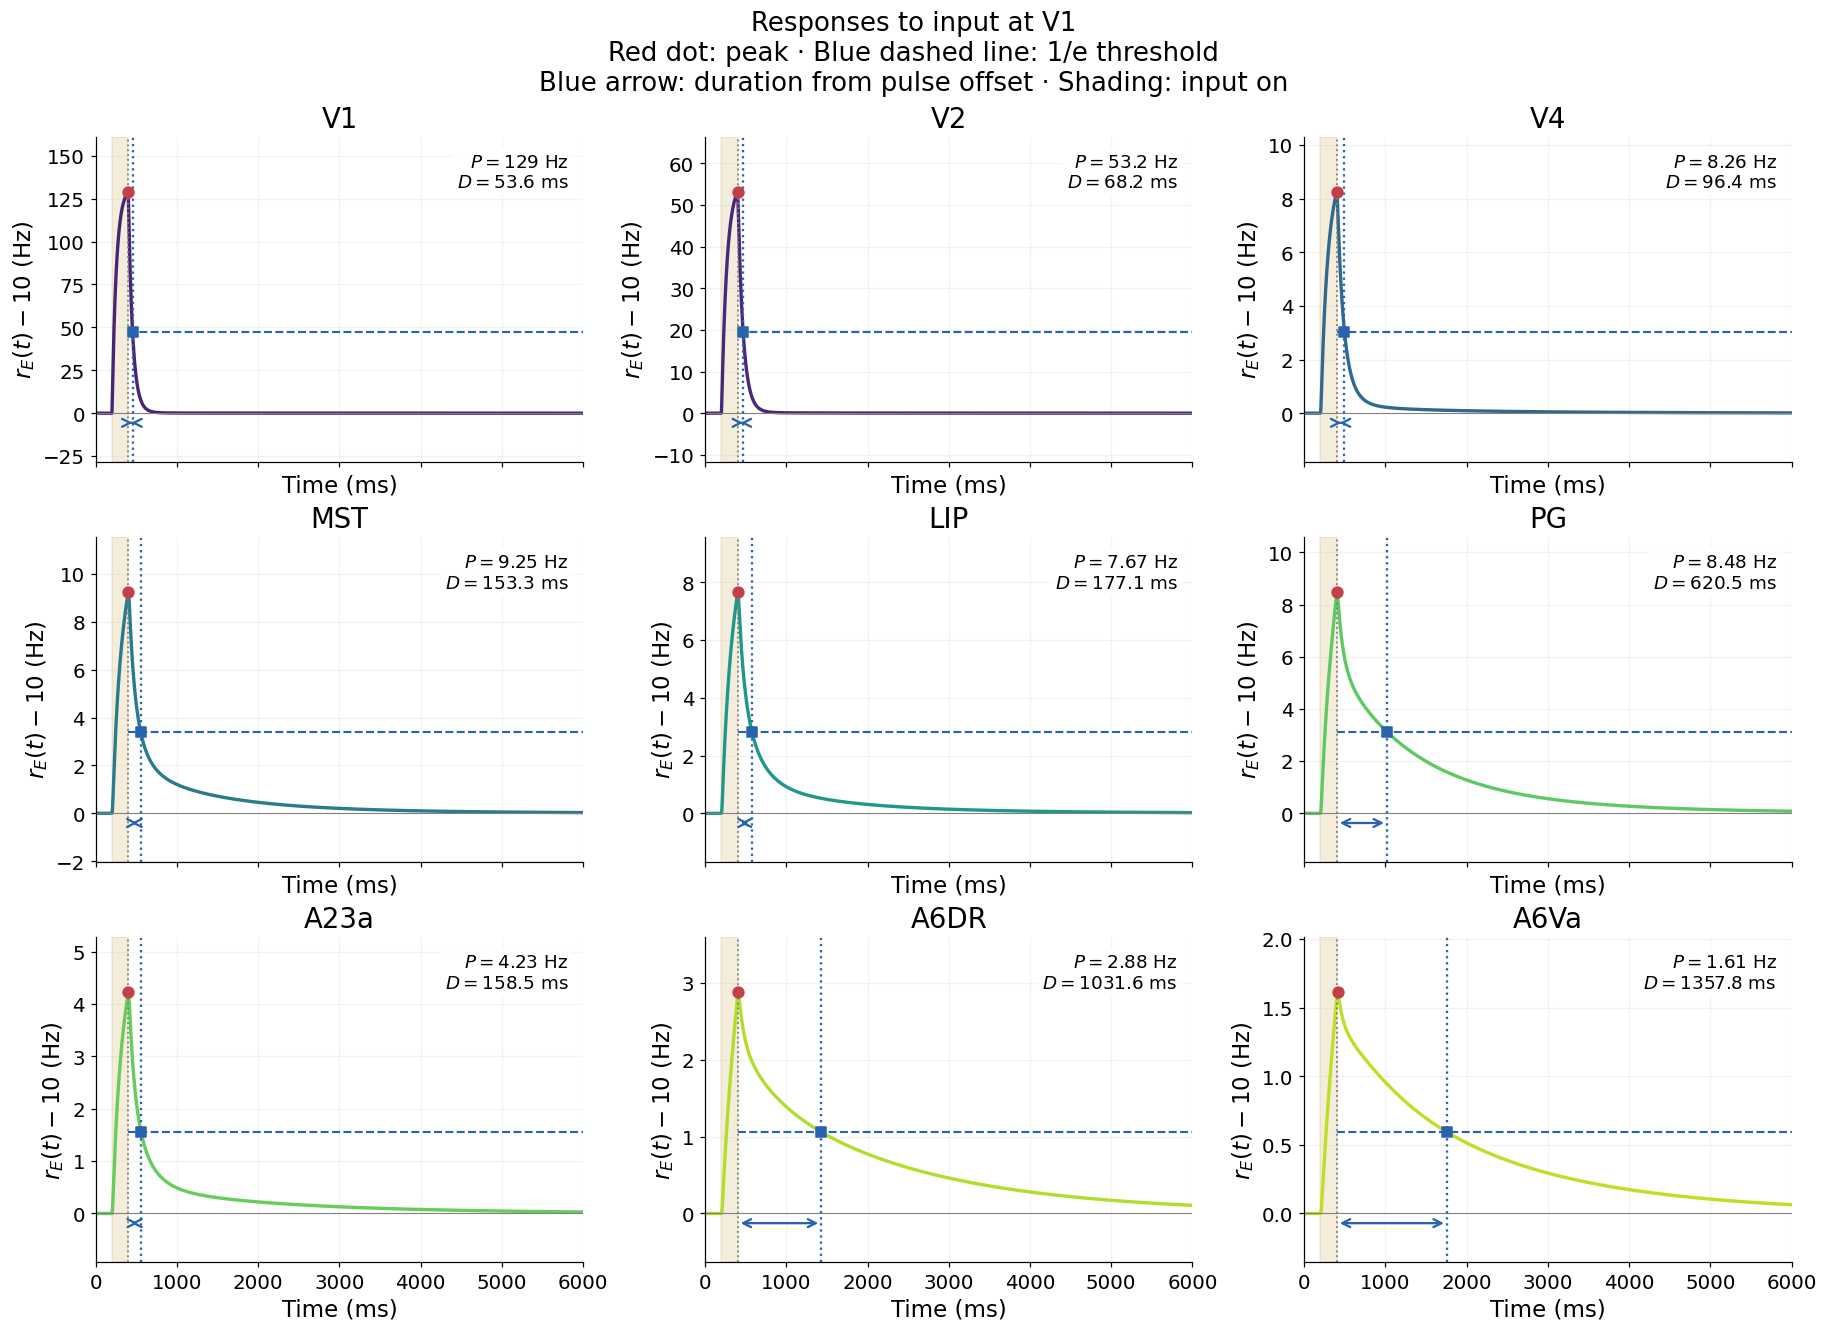

In [5]:
T_SIM = 6000  # ms
response_cache = {}
area_colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(areas)))


def get_response_metrics(source):
    if source in response_cache:
        data = response_cache[source]
        return data["peak"], data["duration"], data["censored"]

    with model_directory(), redirect_stdout(io.StringIO()):
        result = pf.run_stimulus(
            copy.deepcopy(model_parameters),
            VISUAL_INPUT=1,
            TOTAL_INPUT=0,
            T=T_SIM,
            PULSE_INPUT=1,
            MACAQUE_CASE=0,
            GATING_PATHWAY=0,
            CONSENSUS_CASE=0,
            stim_area=source,
            plot_Flag=0,
        )

    stimulus, r_exc, _, source_idx, dt, time, _, peak = result
    r_exc = np.asarray(r_exc)
    time = np.asarray(time)
    peak = np.asarray(peak).reshape(-1)

    if not np.isfinite(r_exc).all():
        raise RuntimeError("Non-finite simulated activity.")

    active = np.flatnonzero(np.abs(stimulus[:, source_idx]) > 0)
    if not len(active):
        raise RuntimeError("No stimulus was applied.")

    offset = active[-1]
    onset_time = time[max(active[0] - 1, 0)]
    offset_time = time[offset]

    # Preserve the original timescale definition.
    minimum_rate = r_exc.min(axis=0)
    post_time = time[offset:-1] - offset_time
    post = r_exc[offset:-1] - minimum_rate

    if len(post_time) < 2:
        raise RuntimeError("Recording must extend beyond stimulus offset.")

    duration = np.full(len(areas), np.nan)
    censored = np.zeros(len(areas), dtype=bool)
    duration_idx = np.full(len(areas), -1, dtype=int)

    post_peak = post.max(axis=0)

    # Threshold expressed on the plotted r_E - 10 Hz axis.
    threshold = minimum_rate - 10.0 + post_peak / np.e

    for j in range(len(areas)):
        if post_peak[j] <= 1e-10:
            continue

        above = np.flatnonzero(post[:, j] > post_peak[j] / np.e)
        if len(above):
            last = above[-1]
            duration[j] = post_time[last]
            duration_idx[j] = offset + last
            censored[j] = last == len(post_time) - 1

    peak_idx = np.argmax(r_exc, axis=0)
    peak_time = time[peak_idx]
    deviation = r_exc - 10.0

    # Retain a compact trace for plotting, while calculating all
    # metrics at the original simulation resolution.
    stride = max(1, int(np.ceil(len(time) / 6001)))
    keep = np.unique(np.concatenate([
        np.arange(0, len(time), stride),
        [len(time) - 1, active[0], offset],
        peak_idx,
        duration_idx[duration_idx >= 0],
    ]))

    duration_y = np.full(len(areas), np.nan)
    valid = duration_idx >= 0
    columns = np.flatnonzero(valid)
    duration_y[valid] = deviation[duration_idx[valid], columns]

    response_cache[source] = {
        "peak": peak,
        "peak_time": peak_time,
        "duration": duration,
        "censored": censored,
        "time": time[keep],
        "deviation": deviation[keep],
        "threshold": threshold,
        "duration_y": duration_y,
        "onset_time": onset_time,
        "offset_time": offset_time,
    }

    return peak, duration, censored


def plot_response_metrics(source, selected):
    selected = list(selected)
    if not selected:
        print("Select at least one output area.")
        return

    peak, duration, censored = get_response_metrics(source)
    data = response_cache[source]

    idx = np.array([areas.index(a) for a in selected], dtype=int)
    x = np.arange(len(idx))

    # --------------------------------------------------------
    # 1. Summary panels
    # --------------------------------------------------------
    fig, axes = plt.subplots(
        1, 2, figsize=(15, 5.5), layout="constrained"
    )

    axes[0].bar(
        x, peak[idx], color=area_colors[idx], width=0.72
    )
    axes[0].set(
        title="Maximal response",
        ylabel="Peak excitatory deviation (Hz)",
    )

    bars = axes[1].bar(
        x, duration[idx], color=area_colors[idx], width=0.72
    )
    axes[1].set(
        title="Timescale",
        ylabel="Post-stimulus 1/e duration (ms)",
    )

    for bar, j in zip(bars, idx):
        center = bar.get_x() + bar.get_width() / 2

        if censored[j]:
            bar.set_hatch("//")
            axes[1].annotate(
                "≥", (center, duration[j]),
                xytext=(0, 3), textcoords="offset points",
                ha="center",
            )
        elif not np.isfinite(duration[j]):
            axes[1].text(
                center, 0.02, "N/A",
                transform=axes[1].get_xaxis_transform(),
                ha="center", fontsize=10,
            )

    for ax in axes:
        ax.set_xticks(x, selected, rotation=45, ha="right")
        ax.set_xlabel("Output area")
        ax.set_ylim(bottom=0)
        ax.margins(y=0.15)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    fig.suptitle(f"Pulse input to {source}", fontsize=21)
    plt.show()

    # --------------------------------------------------------
    # 2. Time series: one panel per selected output area
    # --------------------------------------------------------
    ncols = min(3, len(idx))
    nrows = int(np.ceil(len(idx) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5.5 * ncols, 4.0 * nrows),
        squeeze=False,
        sharex=True,
        layout="constrained",
    )

    time = data["time"]
    offset_time = data["offset_time"]

    for ax, j in zip(axes.ravel(), idx):
        color = area_colors[j]
        trace = data["deviation"][:, j]

        ax.plot(time, trace, color=color, lw=2.2)
        ax.axhline(0, color="gray", lw=0.7)

        # Original square-pulse interval.
        ax.axvspan(
            data["onset_time"], offset_time,
            color="#bb8b18", alpha=0.15,
        )
        ax.axvline(
            offset_time, color="gray", ls=":", lw=1.2
        )

        # Maximal response above the 10 Hz baseline.
        ax.scatter(
            data["peak_time"][j], peak[j],
            color="#c34048", s=50, zorder=5,
        )

        note = rf"$P={peak[j]:.3g}$ Hz"

        if np.isfinite(duration[j]):
            end_time = offset_time + duration[j]
            relation = r"\geq" if censored[j] else "="

            # Threshold uses the original minimum-rate baseline,
            # converted to the deviation coordinates of this plot.
            ax.hlines(
                data["threshold"][j],
                offset_time, T_SIM,
                color="#2864ad", ls="--", lw=1.4,
            )
            ax.axvline(
                end_time,
                color="#2864ad", ls=":", lw=1.5,
            )
            ax.scatter(
                end_time, data["duration_y"][j],
                color="#2864ad", marker="s", s=35, zorder=5,
            )

            # Arrow length represents duration measured from offset,
            # not elapsed time from stimulus onset.
            transform = ax.get_xaxis_transform()
            ax.annotate(
                "",
                xy=(end_time, 0.12),
                xytext=(offset_time, 0.12),
                xycoords=transform,
                textcoords=transform,
                arrowprops={
                    "arrowstyle": "<->",
                    "color": "#2864ad",
                    "lw": 1.5,
                },
            )

            note += "\n" + (
                rf"$D{relation}{duration[j]:.1f}$ ms"
            )
        else:
            note += "\nDuration: N/A"

        ax.text(
            0.97, 0.95, note,
            transform=ax.transAxes,
            ha="right", va="top", fontsize=12,
            bbox={
                "facecolor": "white",
                "edgecolor": "none",
                "alpha": 0.85,
                "pad": 3,
            },
        )

        ax.set(
            title=areas[j],
            xlabel="Time (ms)",
            ylabel=r"$r_E(t)-10$ (Hz)",
            xlim=(0, T_SIM),
        )

        # Individual vertical scales preserve visibility of weak responses.
        low = min(0.0, trace.min())
        high = max(0.0, trace.max())
        span = max(high - low, 1e-6)
        ax.set_ylim(low - 0.22 * span, high + 0.25 * span)
        ax.grid(alpha=0.15)

    for ax in axes.ravel()[len(idx):]:
        ax.axis("off")

    fig.suptitle(
        f"Responses to input at {source}\n"
        "Red dot: peak · Blue dashed line: 1/e threshold\n"
        "Blue arrow: duration from pulse offset · Shading: input on",
        fontsize=17,
    )
    plt.show()

    if censored[idx].any():
        print(
            "Hatched bars and ≥ labels indicate durations "
            "extending beyond the recording."
        )


preferred = [
    "V1", "V2", "V4", "MST", "LIP",
    "PG", "A23a", "A6DR", "A6Va",
]
default_targets = tuple(
    a for a in preferred if a in areas
) or tuple(areas[:6])

default_source = "V1" if "V1" in areas else areas[0]

# Static example; also caches results for the interactive controls.
plot_response_metrics(default_source, default_targets)

## 5 · Interactive experiment

In [6]:
source_control = widgets.Dropdown(options=areas, value=default_source,
    description="Input area", style={"description_width": "initial"},
    layout=widgets.Layout(width="350px"))
target_control = widgets.SelectMultiple(options=areas, value=default_targets,
    description="Output areas", rows=10, style={"description_width": "initial"},
    layout=widgets.Layout(width="350px"))
run_button = widgets.Button(description="Run / update", icon="play", button_style="primary")
plot_output = widgets.Output()

def update_plot(_=None):
    with plot_output:
        clear_output(wait=True)
        selected = list(target_control.value)
        if not selected:
            print("Select at least one output area.")
            return
        for control in (source_control, target_control, run_button):
            control.disabled = True
        try:
            source = source_control.value
            if source not in response_cache:
                print(f"Simulating input to {source}…")
                get_response_metrics(source)
            clear_output(wait=True)
            plot_response_metrics(source, selected)
        except Exception:
            traceback.print_exc()
        finally:
            for control in (source_control, target_control, run_button):
                control.disabled = False

run_button.on_click(update_plot)
display(widgets.VBox([source_control, target_control, run_button, plot_output]))
update_plot()